# Explore the diabetes data (optional)

**Prince Hands-on Lab – Explore the Azure Machine Learning workspace**

This optional notebook looks at the data AutoML trains on, then trains two simple models yourself, so you can see *why* AutoML's best model wins.

**How to run it (free):**
- **VS Code:** open the repo folder, open this file, click **Select Kernel** (top right) → pick a Python environment where you ran `pip install -r requirements.txt` → **Run All**.
- **Jupyter:** in a terminal in the repo folder run `pip install -r requirements.txt notebook`, then `jupyter notebook`, and open `notebooks/explore-diabetes-data.ipynb`.
- **Google Colab:** upload this notebook *and* `data/diabetes-data/diabetes.csv`; the first code cell finds the CSV next to the notebook.

> Running it in Azure ML Studio *Notebooks* needs a compute instance, which costs money every hour it runs. If you do that, **stop/delete the compute instance afterwards**.

## 1. Load the data

In [1]:
from pathlib import Path
import pandas as pd

# Works whether you start Jupyter in the repo root, in notebooks/, or in Colab
candidates = [Path("../data/diabetes-data/diabetes.csv"),
              Path("data/diabetes-data/diabetes.csv"),
              Path("diabetes.csv")]
csv_path = next((p for p in candidates if p.exists()), None)
assert csv_path is not None, "diabetes.csv not found - open the notebook from inside the repo folder"

df = pd.read_csv(csv_path)
print(df.shape)
df.head()

(10000, 10)


,PatientID,Pregnancies,PlasmaGlucose,DiastolicBloodPressure,TricepsThickness,SerumInsulin,BMI,DiabetesPedigree,Age,Diabetic
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


## 2. Check the target column and missing values

About a third of patients are diabetic. The classes are imbalanced but not extremely, which is one of the things AutoML's *data guardrails* check.

In [2]:
print(df["Diabetic"].value_counts(normalize=True).rename("share").round(3))
print("\nMissing values in the whole table:", int(df.isna().sum().sum()))

Diabetic
0    0.666
1    0.334
Name: share, dtype: float64

Missing values in the whole table: 0


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
PatientID,10000.0,1502122.08,289286.76,1000038.00,1251672.25,1504394.00,1754607.50,1999997.00
Pregnancies,10000.0,3.26,3.41,0.00,0.00,2.00,6.00,14.00
PlasmaGlucose,10000.0,107.85,31.92,44.00,84.00,105.00,129.00,192.00
DiastolicBloodPressure,10000.0,71.21,16.80,24.00,58.00,72.00,85.00,117.00
TricepsThickness,10000.0,28.82,14.51,7.00,15.00,31.00,41.00,92.00
SerumInsulin,10000.0,139.24,133.78,14.00,39.00,85.00,197.00,796.00
BMI,10000.0,31.57,9.80,18.20,21.25,31.92,39.33,56.03
DiabetesPedigree,10000.0,0.40,0.38,0.08,0.14,0.20,0.62,2.30
Age,10000.0,30.13,12.11,21.00,22.00,24.00,35.00,77.00
Diabetic,10000.0,0.33,0.47,0.00,0.00,0.00,1.00,1.00


## 3. Which features differ most between diabetic and non-diabetic patients?

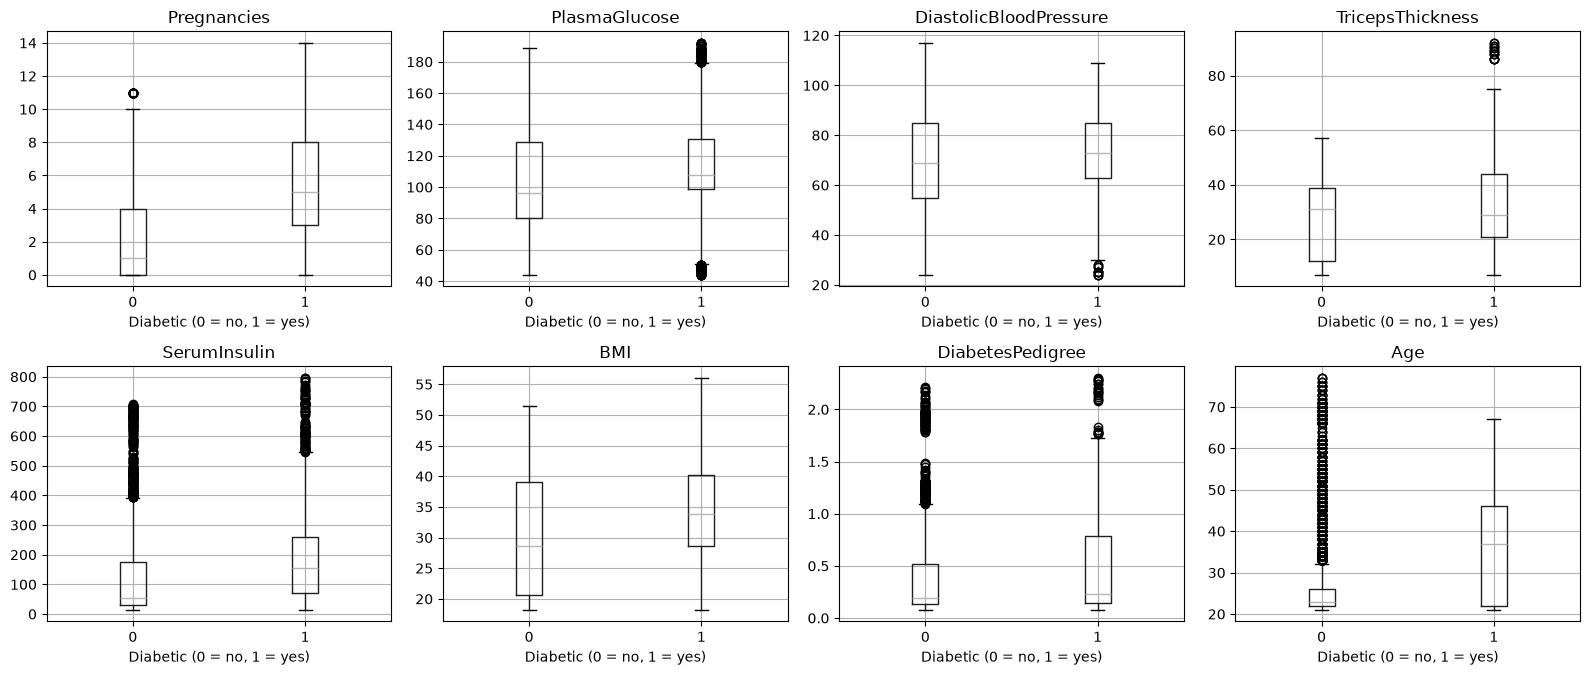

In [4]:
import matplotlib.pyplot as plt

features = ["Pregnancies", "PlasmaGlucose", "DiastolicBloodPressure", "TricepsThickness",
            "SerumInsulin", "BMI", "DiabetesPedigree", "Age"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    df.boxplot(column=col, by="Diabetic", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Diabetic (0 = no, 1 = yes)")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 4. Train two baseline models (same 90/10 split as the AutoML job)

In [5]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["PatientID", "Diabetic"])   # PatientID is just an identifier
y = df["Diabetic"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.10, random_state=42, stratify=y)

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=42),
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({"model": name,
                 "accuracy": accuracy_score(y_test, model.predict(X_test)),
                 "auc": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])})
pd.DataFrame(rows).round(3)

,model,accuracy,auc
0,Logistic regression,0.791,0.869
1,Gradient boosting,0.965,0.992


## 5. What to take away

- A simple linear model reaches roughly **0.79** accuracy. A tree-based boosting model reaches roughly **0.96**.
- AutoML tries many such algorithms and preprocessing steps automatically and ranks them. Compare these numbers with the best model on your AutoML job's **Overview** tab.
- This is *classification model selection*: picking the algorithm and preprocessing that perform best for the task.